# Predictive Maintenance: From Model Value to a Streamlit App

In this lesson, you will build a model that ranks machines by failure risk and translate its predictions into a preventive-maintenance decision.

By the end of the notebook, you will:

- build preprocessing and classification pipelines;
- compare models using ROC AUC, average precision, gain, lift, and profit;
- choose an intervention threshold using a hypothetical cost-benefit model;
- save the complete fitted pipeline with `pickle`;
- generate a Streamlit application with Jupyter's `%%writefile` magic; and
- prepare the files needed for GitHub and Streamlit Community Cloud.

**Dataset:** [UCI AI4I 2020 Predictive Maintenance](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)


**FORM**: [Fill this out](https://docs.google.com/forms/d/e/1FAIpQLSfxgZDpvUOWibGXpBG_8fyb0RBzNr4-MMrDAsAXBESFqkyxYw/viewform?usp=sharing&ouid=106596295392954890759)

## Business scenario

A manufacturer cannot perform preventive maintenance on every machine. Management wants to rank machines by failure risk and service only the machines for which intervention is expected to create value.

For this exercise, assume:

| Assumption | Value |
|---|---:|
| Preventive-maintenance cost | \$500 |
| Cost of an unplanned failure | \$10,000 |
| Probability maintenance prevents a failure | 80% |

Relative to doing nothing:

- maintaining a machine that would fail has an expected incremental value of `0.80 * 10,000 - 500 = $7,500`;
- maintaining a machine that would not fail costs `$500`;
- machines not selected for maintenance receive an incremental value of `$0` in the ranking-based profit curve.

These figures are hypothetical. A real organization would estimate them from maintenance, downtime, labor, safety, and production records.


In [21]:
# Run this only if your environment is missing a required package.
# %pip install pandas numpy matplotlib seaborn scikit-learn streamlit


In [22]:
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from sklearn.compose import make_column_transformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 11

## Load and inspect the data

The download is a ZIP archive containing one CSV file, so `pandas` can read it directly.

### Before running the next cells

1. Identify the target.
2. Identify columns that are merely identifiers.
3. Identify columns that would reveal the answer and cause target leakage.
4. Predict whether accuracy will be a useful primary metric.


In [23]:
DATA_URL = (
    "https://archive.ics.uci.edu/static/public/601/"
    "ai4i+2020+predictive+maintenance+dataset.zip"
)

df = pd.read_csv(DATA_URL, compression="zip")
df.head()


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [24]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

display(df.dtypes.to_frame("dtype"))
display(df.isna().sum().to_frame("missing"))

failure_counts = df["Machine failure"].value_counts().sort_index()
display(failure_counts.to_frame("machines"))

failure_rate = df["Machine failure"].mean()
print(f"Overall failure rate: {failure_rate:.2%}")


Rows: 10,000
Columns: 14


,dtype
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


,missing
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


,machines
Machine failure,
0,9661
1,339


Overall failure rate: 3.39%


## 2. Define the modeling features

`UID` and `Product ID` identify observations rather than describing operating conditions.

`TWF`, `HDF`, `PWF`, `OSF`, and `RNF` describe the failure modes used to construct the overall failure target. Including them would leak the answer into the predictors.


In [25]:
target = "Machine failure"

feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

X = df[feature_columns].copy()
y = df[target].copy()

X.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


## Create training, validation, and test sets

We will:

- fit models on the training set;
- choose the model and profit threshold on the validation set; and
- use the test set once for a final estimate of performance.


In [26]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    stratify=y,
    random_state=RANDOM_STATE,
)

X_validation, X_test, y_validation, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_validation), len(X_test)],
    "failure_rate": [y_train.mean(), y_validation.mean(), y_test.mean()],
}, index=["train", "validation", "test"])

split_summary

,rows,failure_rate
train,6000,0.033833
validation,2000,0.034000
test,2000,0.034000


## Build two complete pipelines

Both pipelines contain preprocessing and a classifier. Saving the entire fitted pipeline means the Streamlit application can send a one-row DataFrame with the original feature names directly to `predict_proba()`.


In [27]:
categorical_features = ["Type"]
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

preprocessor = make_column_transformer(
    (
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features,
    ),
    (
        StandardScaler(),
        numeric_features,
    ),
)

models = {
    "Logistic regression": Pipeline([
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        ),
    ]),
    "Random forest": Pipeline([
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                min_samples_leaf=3,
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]),
}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    print(f"Fitted {name}")


Fitted Logistic regression
Fitted Random forest


## 5. Define lift, gain, and profit

The functions below rank observations from the largest predicted failure probability to the smallest.

- **Cumulative gain**: the proportion of all actual failures found after targeting a given proportion of machines.
- **Lift**: the failure concentration in the targeted group relative to random targeting.
- **Cumulative incremental profit**: the running economic value of maintaining machines in ranked order.


In [28]:
MAINTENANCE_COST = 500
FAILURE_COST = 10_000
MAINTENANCE_EFFECTIVENESS = 0.80


def make_ranking_table(
    y_true,
    y_score,
    maintenance_cost=MAINTENANCE_COST,
    failure_cost=FAILURE_COST,
    effectiveness=MAINTENANCE_EFFECTIVENESS,
):
    ranking = pd.DataFrame({
        "actual": np.asarray(y_true),
        "score": np.asarray(y_score),
    })

    ranking = ranking.sort_values(
        "score",
        ascending=False,
    ).reset_index(drop=True)

    ranking["machines_targeted"] = np.arange(1, len(ranking) + 1)
    ranking["targeted_fraction"] = (
        ranking["machines_targeted"] / len(ranking)
    )

    total_failures = ranking["actual"].sum()
    ranking["failures_found"] = ranking["actual"].cumsum()
    ranking["cumulative_gain"] = (
        ranking["failures_found"] / total_failures
    )
    ranking["lift"] = (
        ranking["cumulative_gain"]
        / ranking["targeted_fraction"]
    )

    true_positive_value = (
        effectiveness * failure_cost
        - maintenance_cost
    )
    false_positive_value = -maintenance_cost

    ranking["incremental_profit"] = np.where(
        ranking["actual"].eq(1),
        true_positive_value,
        false_positive_value,
    )
    ranking["cumulative_profit"] = (
        ranking["incremental_profit"].cumsum()
    )

    return ranking


def summarize_model(name, fitted_model, X_eval, y_eval):
    scores = fitted_model.predict_proba(X_eval)[:, 1]
    ranking = make_ranking_table(y_eval, scores)

    top_ten_count = max(1, int(np.ceil(0.10 * len(ranking))))
    top_ten = ranking.iloc[top_ten_count - 1]
    best = ranking.loc[ranking["cumulative_profit"].idxmax()]

    summary = {
        "model": name,
        "roc_auc": roc_auc_score(y_eval, scores),
        "average_precision": average_precision_score(y_eval, scores),
        "gain_at_10pct": top_ten["cumulative_gain"],
        "lift_at_10pct": top_ten["lift"],
        "max_validation_profit": best["cumulative_profit"],
        "profit_optimal_fraction": best["targeted_fraction"],
        "profit_optimal_threshold": best["score"],
    }

    return summary, ranking


In [29]:
validation_summaries = []
validation_rankings = {}

for name, fitted_model in models.items():
    summary, ranking = summarize_model(
        name,
        fitted_model,
        X_validation,
        y_validation,
    )
    validation_summaries.append(summary)
    validation_rankings[name] = ranking

comparison = (
    pd.DataFrame(validation_summaries)
    .set_index("model")
    .sort_values("max_validation_profit", ascending=False)
)

comparison_display = comparison.copy()
comparison_display["gain_at_10pct"] *= 100
comparison_display["profit_optimal_fraction"] *= 100

comparison_display = comparison_display.rename(columns={
    "gain_at_10pct": "gain_at_10pct_percent",
    "profit_optimal_fraction": "profit_optimal_fraction_percent",
})

comparison_display.round({
    "roc_auc": 3,
    "average_precision": 3,
    "gain_at_10pct_percent": 1,
    "lift_at_10pct": 2,
    "max_validation_profit": 0,
    "profit_optimal_fraction_percent": 1,
    "profit_optimal_threshold": 3,
})


,roc_auc,average_precision,gain_at_10pct_percent,lift_at_10pct,max_validation_profit,profit_optimal_fraction_percent,profit_optimal_threshold
model,,,,,,,
Random forest,0.984,0.808,94.1,9.41,430500.0,8.2,0.098
Logistic regression,0.923,0.449,75.0,7.50,317500.0,11.5,0.071


### Interpretation checkpoint

For each model, complete the following statements:

1. Targeting the top 10% of machines identifies approximately ___% of failures.
2. The lift at 10% is ___, meaning that ________________________________.
3. The profit curve recommends maintaining approximately ___% of machines.
4. The estimated incremental profit on the validation set is $__________.
5. The model with the highest ROC AUC **does / does not** also produce the highest profit.


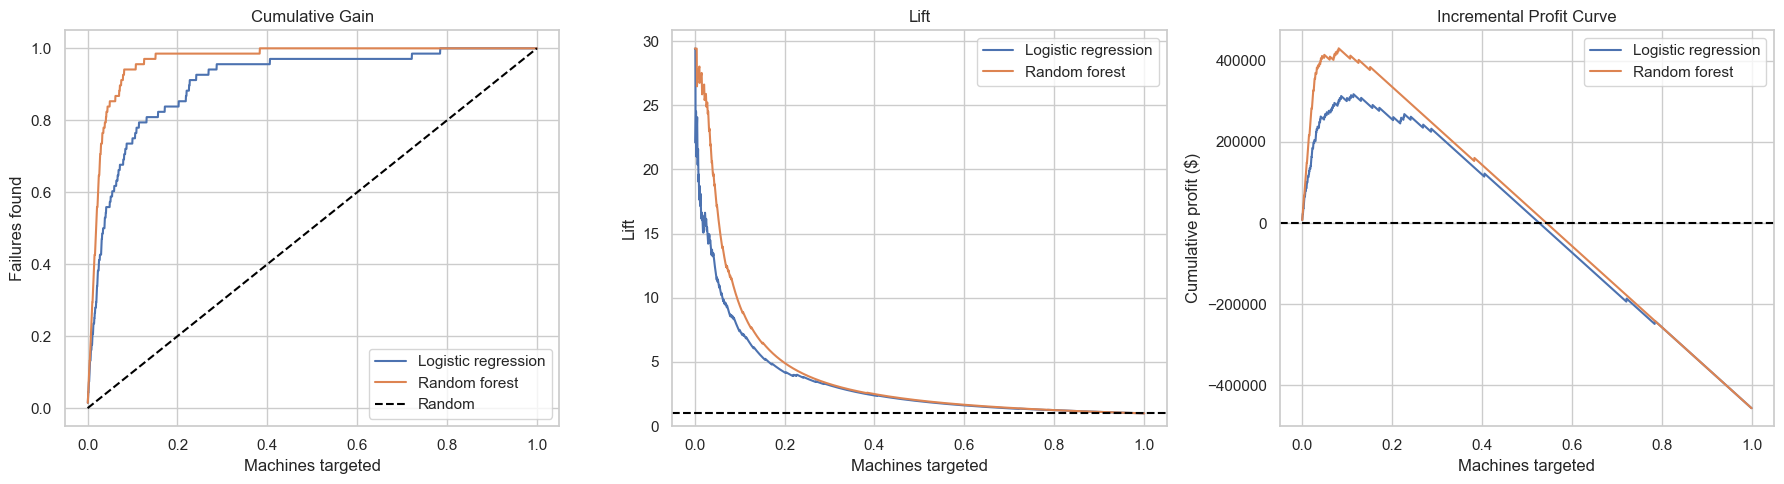

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for name, ranking in validation_rankings.items():
    axes[0].plot(
        ranking["targeted_fraction"],
        ranking["cumulative_gain"],
        label=name,
    )
    axes[1].plot(
        ranking["targeted_fraction"],
        ranking["lift"],
        label=name,
    )
    axes[2].plot(
        ranking["targeted_fraction"],
        ranking["cumulative_profit"],
        label=name,
    )

axes[0].plot([0, 1], [0, 1], "--", color="black", label="Random")
axes[0].set(title="Cumulative Gain", xlabel="Machines targeted", ylabel="Failures found")

axes[1].axhline(1, linestyle="--", color="black")
axes[1].set(title="Lift", xlabel="Machines targeted", ylabel="Lift")
axes[1].set_ylim(bottom=0)

axes[2].axhline(0, linestyle="--", color="black")
axes[2].set(
    title="Incremental Profit Curve",
    xlabel="Machines targeted",
    ylabel="Cumulative profit ($)",
)

for axis in axes:
    axis.legend()

plt.tight_layout()
plt.show()


## Select the model and evaluate once on the test set

The model and decision threshold are chosen using validation profit. We now apply that unchanged policy to the held-out test set.


In [31]:
best_model_name = comparison.index[0]
best_model = models[best_model_name]
best_threshold = comparison.loc[
    best_model_name,
    "profit_optimal_threshold",
]

test_scores = best_model.predict_proba(X_test)[:, 1]
test_decisions = (test_scores >= best_threshold).astype(int)

print(f"Selected model: {best_model_name}")
print(f"Validation-selected threshold: {best_threshold:.4f}")
print(f"Test ROC AUC: {roc_auc_score(y_test, test_scores):.3f}")
print(f"Test average precision: {average_precision_score(y_test, test_scores):.3f}")
print()
print(classification_report(y_test, test_decisions, digits=3))

test_confusion = pd.DataFrame(
    confusion_matrix(y_test, test_decisions),
    index=["Actual: no failure", "Actual: failure"],
    columns=["Decision: do nothing", "Decision: maintain"],
)

test_confusion


Selected model: Random forest
Validation-selected threshold: 0.0981
Test ROC AUC: 0.983
Test average precision: 0.835

              precision    recall  f1-score   support

           0      0.996     0.937     0.965      1932
           1      0.330     0.882     0.480        68

    accuracy                          0.935      2000
   macro avg      0.663     0.910     0.723      2000
weighted avg      0.973     0.935     0.949      2000



,Decision: do nothing,Decision: maintain
Actual: no failure,1810,122
Actual: failure,8,60


In [32]:
test_ranking = make_ranking_table(y_test, test_scores)

selected = pd.DataFrame({
    "actual": np.asarray(y_test),
    "score": test_scores,
    "maintain": test_decisions,
})

selected_profit = np.where(
    selected["maintain"].eq(0),
    0,
    np.where(
        selected["actual"].eq(1),
        MAINTENANCE_EFFECTIVENESS * FAILURE_COST - MAINTENANCE_COST,
        -MAINTENANCE_COST,
    ),
).sum()

print(f"Machines selected for maintenance: {test_decisions.sum():,}")
print(f"Share selected: {test_decisions.mean():.1%}")
print(f"Estimated test-set incremental profit: ${selected_profit:,.0f}")


Machines selected for maintenance: 182
Share selected: 9.1%
Estimated test-set incremental profit: $389,000


## Save the complete model bundle

The pickle contains:

- the fitted preprocessing and classifier pipeline;
- the validation-selected decision threshold;
- the model name;
- the feature schema;
- the hypothetical economic assumptions; and
- the scikit-learn version used to create it.



In [33]:
model_bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "threshold": float(best_threshold),
    "features": feature_columns,
    "maintenance_cost": MAINTENANCE_COST,
    "failure_cost": FAILURE_COST,
    "maintenance_effectiveness": MAINTENANCE_EFFECTIVENESS,
    "sklearn_version": sklearn.__version__,
}

with open("predictive_maintenance_model.pkl", 'wb') as f:
    pickle.dump(model_bundle, f)

print(f"Saved {MODEL_PATH.resolve()}")
print(f"File size: {MODEL_PATH.stat().st_size / 1024:.1f} KB")


Saved /Users/jacobkoehler/Desktop/fall_26/bootcamp/predictive_maintenance_model.pkl
File size: 5115.0 KB


In [34]:
# Verify that the saved object can be loaded and used.
with open("predictive_maintenance_model.pkl", "rb") as f:
    reloaded_bundle = pickle.load(f)

sample_machine = X_test.iloc[[0]]
sample_score = reloaded_bundle["model"].predict_proba(sample_machine)[0, 1]

print(f"Reloaded model: {reloaded_bundle['model_name']}")
print(f"Sample failure probability: {sample_score:.2%}")
print(f"Maintenance threshold: {reloaded_bundle['threshold']:.2%}")


Reloaded model: Random forest
Sample failure probability: 1.11%
Maintenance threshold: 9.81%


## 8. Generate the Streamlit application

The next cell uses Jupyter's `%%writefile` magic. Running the cell creates `app.py` in the notebook's current working directory.


In [35]:
%%writefile app.py
from pathlib import Path
import pickle

import pandas as pd
import streamlit as st


st.set_page_config(
    page_title="Predictive Maintenance",
    page_icon="🛠️",
    layout="centered",
)

st.title("Predictive Maintenance Decision Tool")
st.write(
    "Enter the current operating conditions for a machine. "
    "The app estimates failure risk and applies the maintenance "
    "threshold selected from the validation-set profit curve."
)


@st.cache_resource
def load_model_bundle():
    with open("predictive_maintenance_model.pkl", "rb") as file:
        return pickle.load(file)


bundle = load_model_bundle()
model = bundle["model"]
threshold = bundle["threshold"]


with st.sidebar:
    st.header("Policy assumptions")
    st.metric("Maintenance cost", f"${bundle['maintenance_cost']:,.0f}")
    st.metric("Failure cost", f"${bundle['failure_cost']:,.0f}")
    st.metric(
        "Maintenance effectiveness",
        f"{bundle['maintenance_effectiveness']:.0%}",
    )
    st.caption(f"Model: {bundle['model_name']}")


with st.form("machine_inputs"):
    machine_type = st.selectbox(
        "Product quality type",
        ["L", "M", "H"],
    )

    air_temperature = st.slider(
        "Air temperature (K)",
        min_value=295.0,
        max_value=305.0,
        value=300.0,
        step=0.1,
    )

    process_temperature = st.slider(
        "Process temperature (K)",
        min_value=305.0,
        max_value=315.0,
        value=310.0,
        step=0.1,
    )

    rotational_speed = st.slider(
        "Rotational speed (rpm)",
        min_value=1100,
        max_value=3000,
        value=1500,
        step=10,
    )

    torque = st.slider(
        "Torque (Nm)",
        min_value=0.0,
        max_value=80.0,
        value=40.0,
        step=0.5,
    )

    tool_wear = st.slider(
        "Tool wear (minutes)",
        min_value=0,
        max_value=260,
        value=100,
        step=1,
    )

    submitted = st.form_submit_button("Evaluate machine")


if submitted:
    machine = pd.DataFrame({
        "Type": [machine_type],
        "Air temperature [K]": [air_temperature],
        "Process temperature [K]": [process_temperature],
        "Rotational speed [rpm]": [rotational_speed],
        "Torque [Nm]": [torque],
        "Tool wear [min]": [tool_wear],
    })

    failure_probability = model.predict_proba(machine)[0, 1]
    recommend_maintenance = failure_probability >= threshold

    left, right = st.columns(2)
    left.metric("Predicted failure risk", f"{failure_probability:.1%}")
    right.metric("Policy threshold", f"{threshold:.1%}")

    if recommend_maintenance:
        st.warning("Recommendation: perform preventive maintenance.")
    else:
        st.success("Recommendation: continue operating and monitor.")

    st.progress(min(float(failure_probability), 1.0))

    with st.expander("How the decision was made"):
        st.write(
            "Machines are ranked by model score. The threshold was selected "
            "on validation data to maximize incremental profit under the "
            "hypothetical maintenance assumptions shown in the sidebar."
        )


Overwriting app.py


## Create the deployment requirements

The scikit-learn version is written dynamically so Community Cloud installs the same version used to create the pickle.


## Test locally

From a terminal opened in the same directory as the notebook:

```bash
streamlit run app.py
```

Confirm that the following three files exist before deploying:

```text
app.py
predictive_maintenance_model.pkl
requirements.txt
```


## 11. Push to GitHub and deploy

Create an empty GitHub repository, then run the following from the project directory:

```bash
git init
git add .
git diff --staged
git commit -m "Build predictive maintenance Streamlit app"
git branch -M main
git remote add origin YOUR_REPOSITORY_URL
git push -u origin main
```

Then:

1. Visit [Streamlit Community Cloud](https://share.streamlit.io).
2. Select **Create app**.
3. Choose the GitHub repository and `main` branch.
4. Enter `app.py` as the entrypoint.
5. In **Advanced settings**, choose the Python version used to create the model.
6. Deploy and test the public application.

### Submission

Submit:

- the GitHub repository URL;
- the deployed Streamlit URL;
- an interpretation of lift at the top 10%;
- the profit-maximizing percentage of machines maintained;
- the estimated test-set incremental profit; and
- one limitation of the cost-benefit assumptions.


## Extension questions

1. Recalculate the profit curve with a maintenance cost of $1,500.
2. Recalculate it with maintenance effectiveness reduced to 50%.
3. Does the same model remain the most profitable?
4. How would you estimate the real cost of a false negative?
5. Add a Streamlit control that lets a manager change the cost assumptions. Explain why changing those values should also change the decision threshold.
6. Compare the validation-selected threshold with the theoretical threshold `maintenance_cost / (effectiveness * failure_cost)`. Why might they differ?
